In [ ]:
!apt-get update -qq
!apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1.0-0 libimath-3-1-29t64 libimath-dev libinput-bin libinput10
  libmd4c0 libmtdev1t64 libopencv-calib3d-dev libopencv-calib3d406t64
  libopencv-contrib-dev libo

In [ ]:
%%writefile 1_sinus_vektor.cpp

#include <iostream>
#include <vector>
#include <cmath>
#include <opencv2/opencv.hpp>
using namespace std;
using namespace cv;

void sinus(vector<double>& v, double A, double faz, double T) {
    for(int i=0; i<v.size(); i++) {
        v[i] = A * sin(2 * 3.14159 * i / T + faz);
    }
}

int main() {
    vector<double> v(128);
    sinus(v, 80, 0, 32);

    Mat img(300, 640, CV_8UC3, Scalar(255,255,255));

    for(int i=0; i<128; i++) {
        int x = i * 5;
        int y = 150 - v[i];

        circle(img, Point(x,y), 2, Scalar(0,0,255), -1);

        if(i>0) {
            int y0 = 150 - v[i-1];
            line(img, Point(x-5,y0), Point(x,y), Scalar(255,0,0), 1);
        }
    }

    imwrite("sinus.png", img);
    return 0;
}


Writing 1_sinus_vektor.cpp


In [ ]:
!g++ 1_sinus_vektor.cpp -o sinus $(pkg-config --cflags --libs opencv4)
!./sinus

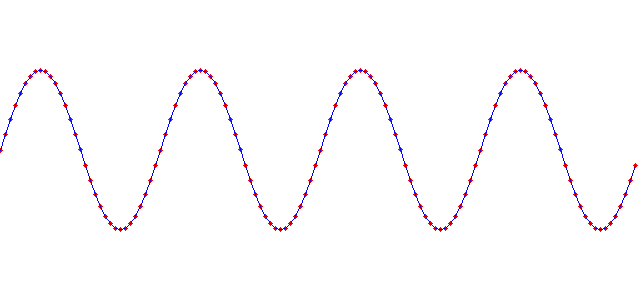

In [ ]:
from IPython.display import Image, display
display(Image("sinus.png"))

In [ ]:

%%writefile urultu_ekle.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <cstdlib>
#include <ctime>
#include <opencv2/opencv.hpp>
using namespace std;
using namespace cv;

void gurultuEkle(vector<double>& v, double oran) {
    if(v.empty() || oran < 0 || oran > 1) return;

    double A = 0;
    for(int i=0; i<v.size(); i++) {
        if(fabs(v[i]) > A)
            A = fabs(v[i]);
    }

    for(int i=0; i<v.size(); i++) {
        double r = (double)rand() / RAND_MAX;
        v[i] += (2*r - 1) * A * oran;
    }
}

int main() {
    srand(time(0));
    vector<double> v(128);

    for(int i=0; i<128; i++) {
        v[i] = 80 * sin(2 * 3.14159 * i / 32);
    }

    gurultuEkle(v, 0.2);

    Mat img(300, 640, CV_8UC3, Scalar(255,255,255));

    for(int i=1; i<128; i++) {
        int y1 = 150 - v[i-1];
        int y2 = 150 - v[i];

        line(img, Point((i-1)*5,y1),
             Point(i*5,y2), Scalar(0,0,255), 2);
    }

    imwrite("gurultu.png", img);
    return 0;
}


Writing urultu_ekle.cpp


In [ ]:
!apt-get install -y libopencv-dev pkg-config

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 59 not upgraded.


In [ ]:
!g++ gurultu_ekle.cpp -o gurultu $(pkg-config --cflags --libs opencv4)
!./gurultu

cc1plus: fatal error: gurultu_ekle.cpp: No such file or directory
compilation terminated.
/bin/bash: line 1: ./gurultu: No such file or directory


In [ ]:
!find /content -type f -name "*.png"


/content/sinus.png


/content/sinus.png


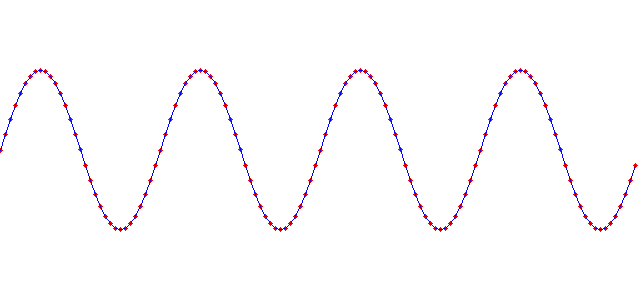

In [ ]:
from IPython.display import Image, display
import glob

images = glob.glob("/content/**/*.png", recursive=True)

if not images:
    print("Aucune image PNG trouvée.")
else:
    for chemin in images:
        print(chemin)
        display(Image(filename=chemin, width=500))

Fonksiyon, vektör ve gürültü oranını alır. Önce maksimum genliği bulur. Sonra her elemana rastgele gürültü ekler. Sonuç grafik olarak gösterilir.

In [ ]:

%%writefile gauss_medyan.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <cstdlib>
#include <algorithm>
#include <opencv2/opencv.hpp>
using namespace std;
using namespace cv;

void gaussFiltre(vector<double>& v, vector<double>& g) {
    int w[5] = {1, 4, 6, 4, 1};
    int n = v.size();
    g.resize(n);

    for(int i=0; i<n; i++) {
        double toplam = 0;
        for(int j=-2; j<=2; j++) {
            int k = max(0, min(n-1, i+j));
            toplam += v[k] * w[j+2];
        }
        g[i] = toplam / 16.0;
    }
}

void medyanFiltre(vector<double>& v, vector<double>& m) {
    int n = v.size();
    m.resize(n);

    for(int i=0; i<n; i++) {
        vector<double> a;
        for(int j=-2; j<=2; j++) {
            int k = max(0, min(n-1, i+j));
            a.push_back(v[k]);
        }
        sort(a.begin(), a.end());
        m[i] = a[2];
    }
}

void ciz(Mat& img, vector<double>& v, int orta, Scalar renk, string ad) {
    putText(img, ad, Point(40, orta-115),
            FONT_HERSHEY_SIMPLEX, 0.65, Scalar(0,0,0), 2);
    line(img, Point(40,orta), Point(860,orta), Scalar(180,180,180), 1);

    for(int i=1; i<v.size(); i++) {
        Point p1(50+(i-1)*6, orta-(int)round(v[i-1]));
        Point p2(50+i*6, orta-(int)round(v[i]));
        line(img, p1, p2, renk, 2);
    }
}

int main() {
    srand(42);
    vector<double> temiz(128), gurultulu(128), gauss, medyan;

    for(int i=0; i<128; i++) {
        temiz[i] = 80 * sin(2 * 3.14159 * i / 32);
        double r = (double)rand() / RAND_MAX;
        gurultulu[i] = temiz[i] + (2*r-1) * 80 * 0.2;
    }

    gaussFiltre(gurultulu, gauss);
    medyanFiltre(gauss, medyan);

    Mat img(900, 900, CV_8UC3, Scalar(255,255,255));

    ciz(img, temiz, 150, Scalar(0,150,0), "Orijinal sinus");
    ciz(img, gurultulu, 355, Scalar(0,0,255), "Gurultulu sinus");
    ciz(img, gauss, 560, Scalar(255,0,0), "Gauss filtresi");
    ciz(img, medyan, 765, Scalar(180,0,180), "Gauss + Medyan");

    imwrite("filtre_sonuclari.png", img);
    return 0;
}


Writing gauss_medyan.cpp


In [ ]:
!apt-get install -y libopencv-dev pkg-config
!g++ gauss_medyan.cpp -o filtre $(pkg-config --cflags --libs opencv4)
!./filtre

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 59 not upgraded.


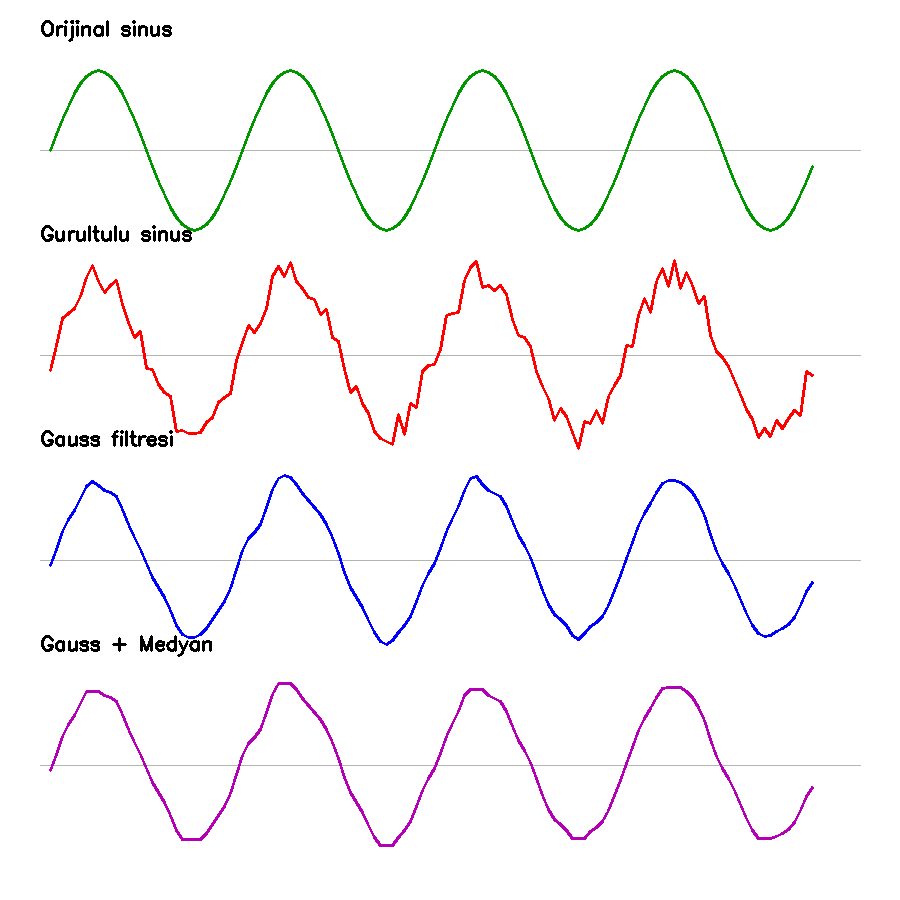

In [ ]:
from IPython.display import Image, display
display(Image("filtre_sonuclari.png"))

Gauss filtresi gürültülü sinyali yumuşatarak rastgele gürültüyü azaltır. Medyan filtresi özellikle ani ve büyük değer değişimlerini gidermede etkilidir. Her iki filtre gürültüyü azaltabilir fakat sinyalin orijinal şeklini de bir miktar değiştirebilir.

In [ ]:
from google.colab import files

files.download("gauss_medyan.cpp")
files.download("filtre_sonuclari.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/dft_harmonik.cpp
#include <iostream>
#include <vector>
#include <complex>
#include <cmath>
#include <random>
#include <fstream>
#include <iomanip>
using namespace std;

vector<complex<double>> DFT(const vector<double>& sinyal) {
    int N = sinyal.size();
    if (N == 0 || (N & (N-1)) != 0) { return {}; }

    double pi = acos(-1.0);
    vector<complex<double>> harmonik(N);

    for (int k = 0; k < N; k++) {
        double reel = 0, imag = 0;

        for (int n = 0; n < N; n++) {
            double aci = 2*pi*k*n/N;
            reel += sinyal[n]*cos(aci);
            imag -= sinyal[n]*sin(aci);
        }

        harmonik[k] = complex<double>(reel, imag);
    }

    return harmonik;
}

int main() {
    int N = 512;
    double fs = 1024, f = 8, A = 10, oran = 0.30;
    double pi = acos(-1.0);

    vector<double> temiz(N), gurultulu(N);

    mt19937 generator(42);
    uniform_real_distribution<double> bruit(-A*oran, A*oran);

    ofstream zaman("/content/dft_signaux.csv");
    zaman << "zaman,temiz,gurultulu\n";
    zaman << setprecision(12);

    for (int n = 0; n < N; n++) {
        double t = n/fs;
        temiz[n] = A*sin(2*pi*f*t);
        gurultulu[n] = temiz[n]+bruit(generator);

        zaman << t << "," << temiz[n] << "," << gurultulu[n] << "\n";
    }

    vector<complex<double>> H1 = DFT(temiz);
    vector<complex<double>> H2 = DFT(gurultulu);

    if (H1.empty() || H2.empty()) { return 1; }

    ofstream spektrum("/content/dft_spectre.csv");
    spektrum << "frekans,temiz,gurultulu\n";
    spektrum << setprecision(12);

    for (int k = 0; k <= N/2; k++) {
        double c = (k == 0 || k == N/2) ? 1.0 : 2.0;
        double a1 = c*abs(H1[k])/N;
        double a2 = c*abs(H2[k])/N;

        spektrum << k*fs/N << "," << a1 << "," << a2 << "\n";
    }

    int k = (int)(f*N/fs);

    cout << fixed << setprecision(3);
    cout << "N = " << N << endl;
    cout << "Temel frekans = " << k*fs/N << " Hz" << endl;
    cout << "Temiz genlik = " << 2.0*abs(H1[k])/N << endl;
    cout << "Gurultulu genlik = " << 2.0*abs(H2[k])/N << endl;

    return 0;
}

Overwriting /content/dft_harmonik.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/dft_harmonik.cpp -o /content/dft && /content/dft

N = 512
Temel frekans = 8.000 Hz
Temiz genlik = 10.000
Gurultulu genlik = 9.927


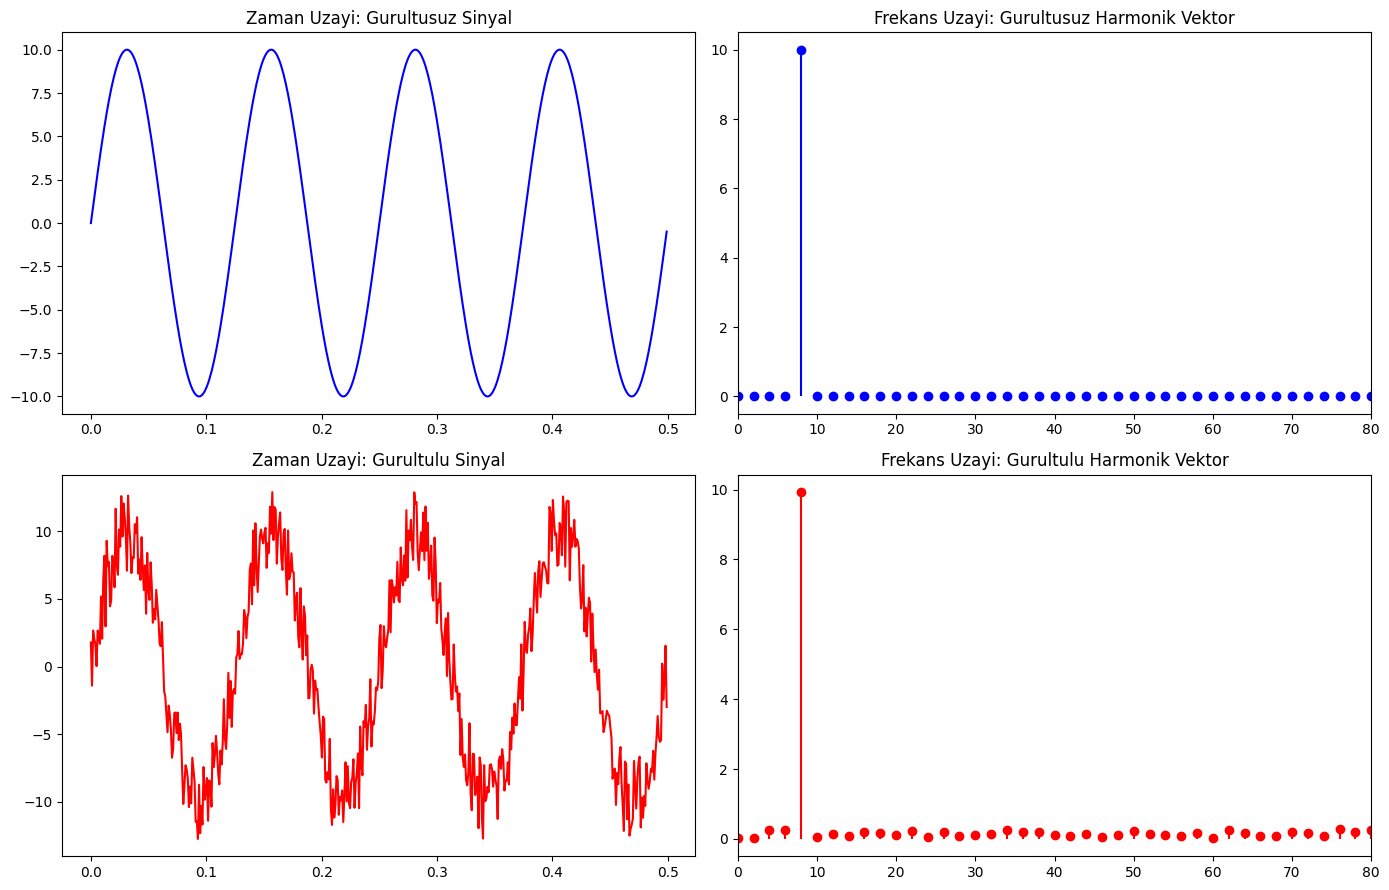

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.genfromtxt("/content/dft_signaux.csv", delimiter=",", names=True)
s = np.genfromtxt("/content/dft_spectre.csv", delimiter=",", names=True)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0,0].plot(z["zaman"], z["temiz"], color="blue")
ax[0,0].set_title("Zaman Uzayi: Gurultusuz Sinyal")

ax[0,1].stem(s["frekans"], s["temiz"],
             linefmt="b-", markerfmt="bo", basefmt=" ")
ax[0,1].set_title("Frekans Uzayi: Gurultusuz Harmonik Vektor")
ax[0,1].set_xlim(0, 80)

ax[1,0].plot(z["zaman"], z["gurultulu"], color="red")
ax[1,0].set_title("Zaman Uzayi: Gurultulu Sinyal")

ax[1,1].stem(s["frekans"], s["gurultulu"],
             linefmt="r-", markerfmt="ro", basefmt=" ")
ax[1,1].set_title("Frekans Uzayi: Gurultulu Harmonik Vektor")
ax[1,1].set_xlim(0, 80)

plt.tight_layout()
plt.savefig("/content/dft_sonuc.png", dpi=200)
plt.show()

In [ ]:
%%writefile /content/dft_iki_sinyal.cpp
#include <iostream>
#include <vector>
#include <complex>
#include <cmath>
#include <random>
#include <fstream>
#include <iomanip>

using namespace std;

vector<complex<double>> DFT(const vector<double>& sinyal) {
    int N = sinyal.size();
    vector<complex<double>> harmonik(N);

    if (N == 0 || (N & (N - 1)) != 0) {
        cout << "Vektor uzunlugu 2'nin kuvveti olmali" << endl;
        return {};
    }

    double pi = acos(-1.0);

    for (int k = 0; k < N; k++) {
        double reel = 0;
        double imag = 0;

        for (int n = 0; n < N; n++) {
            double aci = 2.0 * pi * k * n / N;
            reel += sinyal[n] * cos(aci);
            imag -= sinyal[n] * sin(aci);
        }

        harmonik[k] = complex<double>(reel, imag);
    }

    return harmonik;
}

double genlik(const vector<complex<double>>& H, int k) {
    int N = H.size();

    double c = 2.0;
    if (k == 0 || k == N / 2) {
        c = 1.0;
    }

    return c * abs(H[k]) / N;
}

int main() {
    int N = 512;
    double fs = 512.0;
    double f1 = 50.0, A1 = 12.0;
    double f2 = 30.0, A2 = 5.0;
    double oran = 0.30;
    double pi = acos(-1.0);

    vector<double> sinyal1(N);
    vector<double> sinyal2(N);
    vector<double> toplam(N);

    mt19937 motor(42);
    uniform_real_distribution<double> rastgele(-1.0, 1.0);

    ofstream zaman("/content/dft_iki_sinyal.csv");

    if (!zaman.is_open()) {
        cout << "CSV dosyasi olusturulamadi" << endl;
        return 1;
    }

    zaman << "zaman,sinyal1,sinyal2,toplam\n";
    zaman << setprecision(12);

    for (int n = 0; n < N; n++) {
        double t = n / fs;

        double gurultu1 = A1 * oran * rastgele(motor);
        double gurultu2 = A2 * oran * rastgele(motor);

        sinyal1[n] = A1 * sin(2 * pi * f1 * t) + gurultu1;
        sinyal2[n] = A2 * sin(2 * pi * f2 * t) + gurultu2;

        toplam[n] = sinyal1[n] + sinyal2[n];

        zaman << t << ","
              << sinyal1[n] << ","
              << sinyal2[n] << ","
              << toplam[n] << "\n";
    }

    zaman.close();

    vector<complex<double>> H1 = DFT(sinyal1);
    vector<complex<double>> H2 = DFT(sinyal2);
    vector<complex<double>> HT = DFT(toplam);

    if (H1.empty() || H2.empty() || HT.empty()) {
        return 1;
    }

    ofstream frekans("/content/dft_iki_harmonik.csv");

    if (!frekans.is_open()) {
        cout << "Harmonik CSV olusturulamadi" << endl;
        return 1;
    }

    frekans << "frekans,h1,h2,ht\n";
    frekans << setprecision(12);

    for (int k = 0; k <= N / 2; k++) {
        double hz = k * fs / N;

        frekans << hz << ","
                << genlik(H1, k) << ","
                << genlik(H2, k) << ","
                << genlik(HT, k) << "\n";
    }

    frekans.close();

    int k1 = (int)round(f1 * N / fs);
    int k2 = (int)round(f2 * N / fs);

    cout << fixed << setprecision(3);

    cout << "Sinyal 1 (50 Hz): " << genlik(H1, k1) << endl;
    cout << "Sinyal 2 (30 Hz): " << genlik(H2, k2) << endl;
    cout << "Toplam 30 Hz: " << genlik(HT, k2) << endl;
    cout << "Toplam 50 Hz: " << genlik(HT, k1) << endl;

    cout << "DFT tamamlandi" << endl;

    return 0;
}

Writing /content/dft_iki_sinyal.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/dft_iki_sinyal.cpp -o /content/dft2 && /content/dft2

Sinyal 1 (50 Hz): 12.057
Sinyal 2 (30 Hz): 5.038
Toplam 30 Hz: 5.273
Toplam 50 Hz: 11.988
DFT tamamlandi


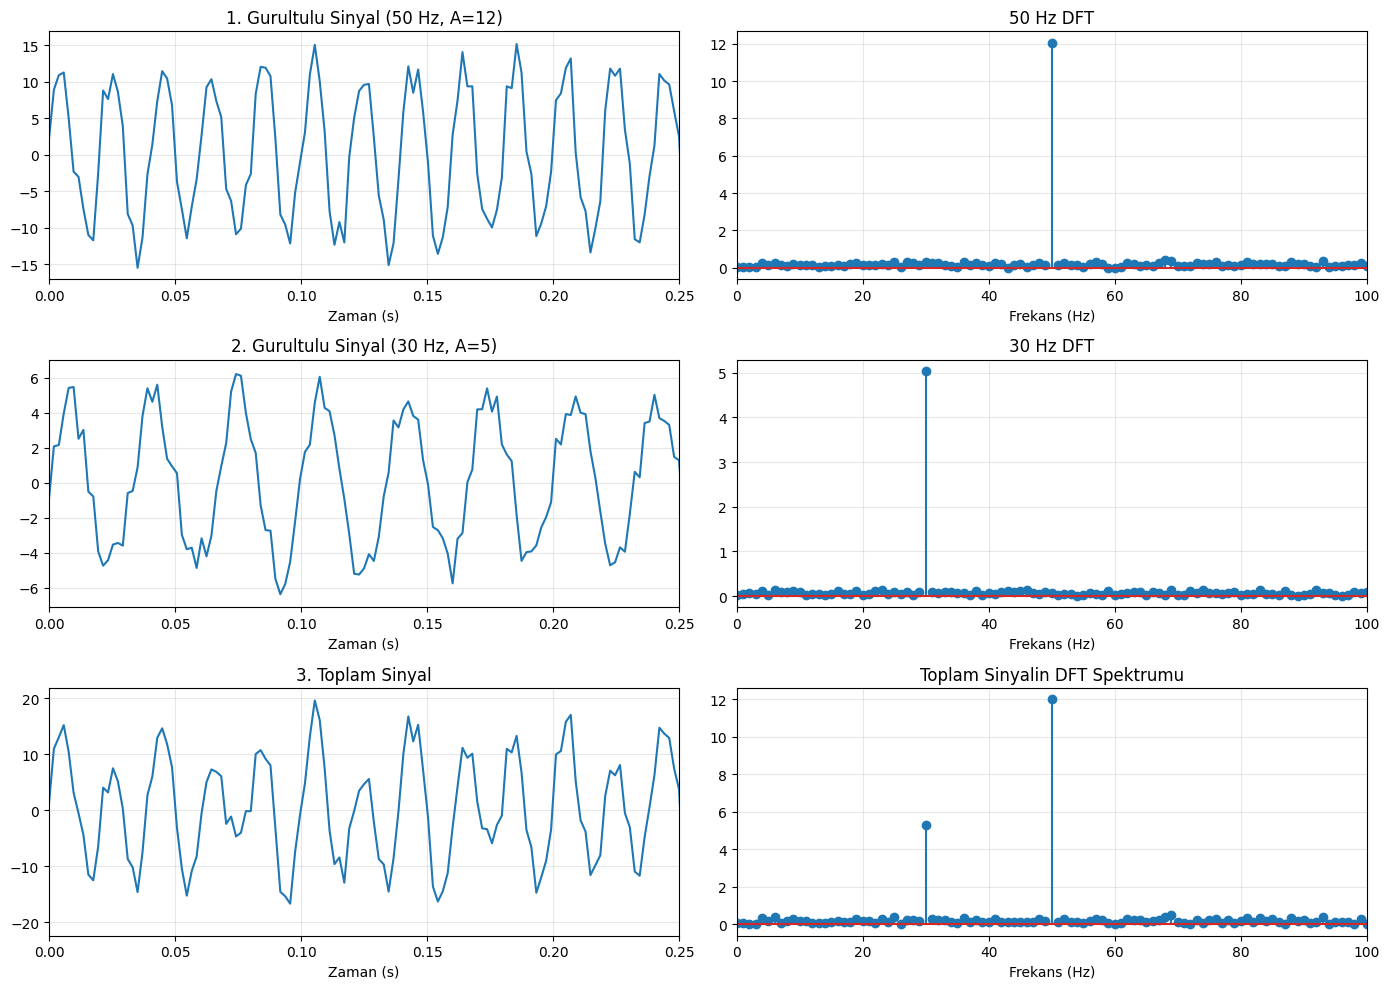

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.genfromtxt("/content/dft_iki_sinyal.csv", delimiter=",", names=True)
s = np.genfromtxt("/content/dft_iki_harmonik.csv", delimiter=",", names=True)

fig, ax = plt.subplots(3, 2, figsize=(14, 10))

veriler = [
    ("sinyal1", "h1", "1. Gurultulu Sinyal (50 Hz, A=12)", "50 Hz DFT"),
    ("sinyal2", "h2", "2. Gurultulu Sinyal (30 Hz, A=5)", "30 Hz DFT"),
    ("toplam", "ht", "3. Toplam Sinyal", "Toplam Sinyalin DFT Spektrumu")
]

for i, (ad, har, baslik1, baslik2) in enumerate(veriler):
    ax[i, 0].plot(z["zaman"], z[ad])
    ax[i, 0].set_title(baslik1)
    ax[i, 0].set_xlabel("Zaman (s)")
    ax[i, 0].set_xlim(0, 0.25)
    ax[i, 0].grid(alpha=0.3)

    ax[i, 1].stem(s["frekans"], s[har])
    ax[i, 1].set_title(baslik2)
    ax[i, 1].set_xlabel("Frekans (Hz)")
    ax[i, 1].set_xlim(0, 100)
    ax[i, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/dft_iki_sinyal_grafikler.png", dpi=200)
plt.show()

In [ ]:
%%writefile /content/frekans_filtresi.cpp
#include <iostream>
#include <vector>
#include <complex>
#include <cmath>
#include <random>
#include <fstream>
#include <iomanip>
using namespace std;

vector<complex<double>> DFT(const vector<double>& sinyal) {
    int N = sinyal.size();
    if (N == 0 || (N & (N - 1)) != 0) { return {}; }

    double pi = acos(-1.0);
    vector<complex<double>> H(N);

    for (int k = 0; k < N; k++) {
        double gercek = 0, sanal = 0;

        for (int n = 0; n < N; n++) {
            double aci = 2*pi*k*n/N;
            gercek += sinyal[n]*cos(aci);
            sanal -= sinyal[n]*sin(aci);
        }

        H[k] = complex<double>(gercek, sanal);
    }

    return H;
}

vector<complex<double>> frekansFiltre(const vector<complex<double>>& H, double esik) {
    int N = H.size();
    vector<complex<double>> sonuc = H;

    for (int k = 0; k <= N/2; k++) {
        double katsayi = (k == 0 || k == N/2) ? 1.0 : 2.0;
        double genlik = katsayi*abs(H[k])/N;

        if (genlik < esik) {
            sonuc[k] = 0;
            if (k > 0 && k < N/2) { sonuc[N-k] = 0; }
        }
    }

    return sonuc;
}

vector<double> IDFT(const vector<complex<double>>& H) {
    int N = H.size();
    double pi = acos(-1.0);
    vector<double> sinyal(N);

    for (int n = 0; n < N; n++) {
        double deger = 0;

        for (int k = 0; k < N; k++) {
            double aci = 2*pi*k*n/N;
            deger += H[k].real()*cos(aci) - H[k].imag()*sin(aci);
        }

        sinyal[n] = deger/N;
    }

    return sinyal;
}

double genlik(const vector<complex<double>>& H, int k) {
    int N = H.size();
    double c = (k == 0 || k == N/2) ? 1.0 : 2.0;
    return c*abs(H[k])/N;
}

double hata(const vector<double>& a, const vector<double>& b) {
    double toplam = 0;

    for (int i = 0; i < (int)a.size(); i++) {
        double fark = a[i]-b[i];
        toplam += fark*fark;
    }

    return sqrt(toplam/a.size());
}

int main() {
    int N = 512;
    double fs = 512, oran = 0.30, esik = 1.0;
    double pi = acos(-1.0);

    vector<double> temiz1(N), temiz2(N), temizToplam(N);
    vector<double> gurultulu1(N), gurultulu2(N), gurultuluToplam(N);

    mt19937 motor(42);
    uniform_real_distribution<double> bruit(-1.0, 1.0);

    for (int n = 0; n < N; n++) {
        double t = n/fs;

        temiz1[n] = 12*sin(2*pi*50*t);
        temiz2[n] = 5*sin(2*pi*30*t);
        temizToplam[n] = temiz1[n]+temiz2[n];

        gurultulu1[n] = temiz1[n]+12*oran*bruit(motor);
        gurultulu2[n] = temiz2[n]+5*oran*bruit(motor);
        gurultuluToplam[n] = gurultulu1[n]+gurultulu2[n];
    }

    vector<complex<double>> H1 = DFT(gurultulu1);
    vector<complex<double>> H2 = DFT(gurultulu2);
    vector<complex<double>> HT = DFT(gurultuluToplam);

    vector<complex<double>> F1 = frekansFiltre(H1, esik);
    vector<complex<double>> F2 = frekansFiltre(H2, esik);
    vector<complex<double>> FT = frekansFiltre(HT, esik);

    vector<double> sonuc1 = IDFT(F1);
    vector<double> sonuc2 = IDFT(F2);
    vector<double> sonucT = IDFT(FT);

    ofstream zaman("/content/frekans_zaman.csv");
    zaman << "zaman,temiz1,gurultulu1,filtre1,temiz2,gurultulu2,filtre2,temizToplam,gurultuluToplam,filtreToplam\n";
    zaman << setprecision(12);

    for (int n = 0; n < N; n++) {
        zaman << n/fs << "," << temiz1[n] << "," << gurultulu1[n] << "," << sonuc1[n]
              << "," << temiz2[n] << "," << gurultulu2[n] << "," << sonuc2[n]
              << "," << temizToplam[n] << "," << gurultuluToplam[n] << "," << sonucT[n] << "\n";
    }

    ofstream spektrum("/content/frekans_spektrum.csv");
    spektrum << "frekans,once1,sonra1,once2,sonra2,onceToplam,sonraToplam\n";
    spektrum << setprecision(12);

    for (int k = 0; k <= N/2; k++) {
        spektrum << k*fs/N << "," << genlik(H1,k) << "," << genlik(F1,k)
                 << "," << genlik(H2,k) << "," << genlik(F2,k)
                 << "," << genlik(HT,k) << "," << genlik(FT,k) << "\n";
    }

    cout << fixed << setprecision(3);
    cout << "Esik = " << esik << endl;
    cout << "50 Hz: " << genlik(H1,50) << " -> " << genlik(F1,50) << endl;
    cout << "30 Hz: " << genlik(H2,30) << " -> " << genlik(F2,30) << endl;
    cout << "Birlesim 30/50 Hz: " << genlik(FT,30) << " / " << genlik(FT,50) << endl;

    cout << "Sinyal 1 RMSE: " << hata(gurultulu1,temiz1)
         << " -> " << hata(sonuc1,temiz1) << endl;

    cout << "Sinyal 2 RMSE: " << hata(gurultulu2,temiz2)
         << " -> " << hata(sonuc2,temiz2) << endl;

    cout << "Toplam RMSE: " << hata(gurultuluToplam,temizToplam)
         << " -> " << hata(sonucT,temizToplam) << endl;

    return 0;
}

Writing /content/frekans_filtresi.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/frekans_filtresi.cpp -o /content/frekans && /content/frekans

Esik = 1.000
50 Hz: 12.057 -> 12.057
30 Hz: 5.038 -> 5.038
Birlesim 30/50 Hz: 5.273 / 11.988
Sinyal 1 RMSE: 2.072 -> 0.236
Sinyal 2 RMSE: 0.835 -> 0.027
Toplam RMSE: 2.216 -> 0.334


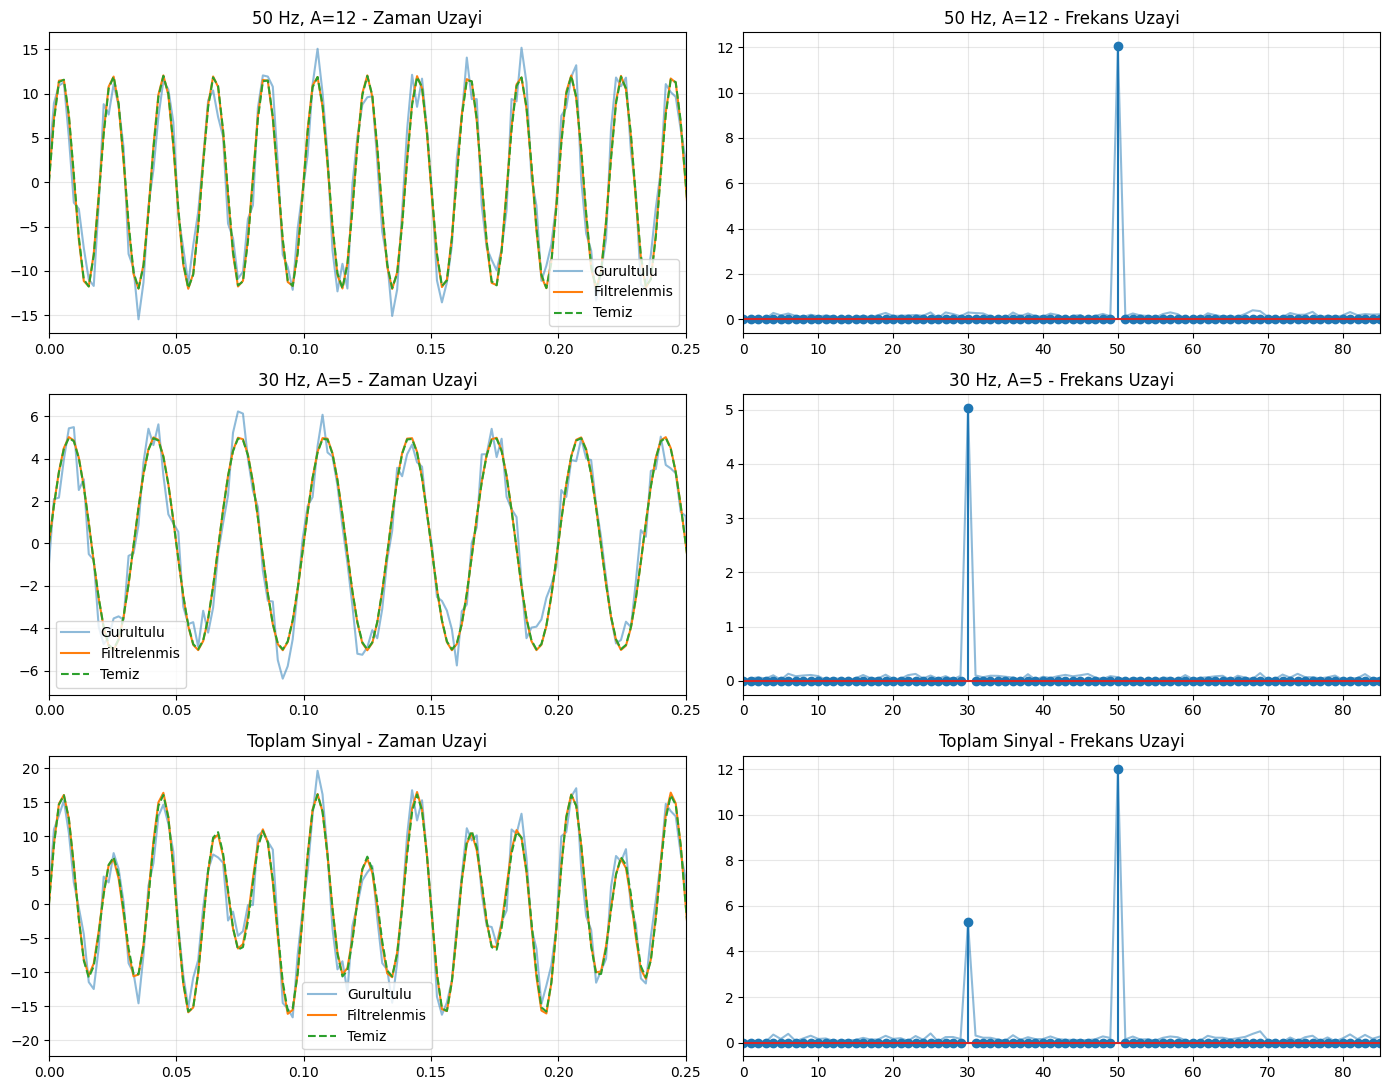

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.genfromtxt("/content/frekans_zaman.csv", delimiter=",", names=True)
s = np.genfromtxt("/content/frekans_spektrum.csv", delimiter=",", names=True)

veriler = [
    ("50 Hz, A=12", "temiz1", "gurultulu1", "filtre1", "once1", "sonra1"),
    ("30 Hz, A=5", "temiz2", "gurultulu2", "filtre2", "once2", "sonra2"),
    ("Toplam Sinyal", "temizToplam", "gurultuluToplam",
     "filtreToplam", "onceToplam", "sonraToplam")
]

fig, ax = plt.subplots(3, 2, figsize=(14, 11))

for i, (titre, temiz, bruit, filtre, once, sonra) in enumerate(veriler):
    ax[i,0].plot(z["zaman"], z[bruit], alpha=0.5, label="Gurultulu")
    ax[i,0].plot(z["zaman"], z[filtre], label="Filtrelenmis")
    ax[i,0].plot(z["zaman"], z[temiz], "--", label="Temiz")
    ax[i,0].set_xlim(0, 0.25)
    ax[i,0].set_title(titre + " - Zaman Uzayi")
    ax[i,0].legend()
    ax[i,0].grid(alpha=0.3)

    ax[i,1].plot(s["frekans"], s[once], label="Once", alpha=0.5)
    ax[i,1].stem(s["frekans"], s[sonra])
    ax[i,1].set_xlim(0, 85)
    ax[i,1].set_title(titre + " - Frekans Uzayi")
    ax[i,1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/frekans_filtresi_grafikler.png", dpi=200)
plt.show()

İki sinyalin toplamına frekans filtresi uygulandığında, hem 30 Hz hem de 50 Hz harmonikleri korunmuştur. Yeniden oluşturulan sinyalin gürültüsü azalmış ve temiz sinyale daha yakın bir sonuç elde edilmiştir.

Sonuç olarak frekans filtresinin, uygun eşik değeri seçildiğinde, sinyaldeki gürültüyü azaltabildiği görülmüştür.

In [ ]:
%%writefile /content/dft_2d.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <fstream>

using namespace cv;
using namespace std;

Mat DFT2D(const Mat& resim) {
    Mat gri;

    if (resim.channels() == 3) {
        cvtColor(resim, gri, COLOR_BGR2GRAY);
    } else {
        gri = resim.clone();
    }

    int h = gri.rows, w = gri.cols;
    double pi = acos(-1.0);

    Mat satir(h, w, CV_64FC2, Scalar(0,0));
    Mat harmonik(h, w, CV_64FC2, Scalar(0,0));

    for (int y = 0; y < h; y++) {
        for (int u = 0; u < w; u++) {
            double reel = 0, imag = 0;

            for (int x = 0; x < w; x++) {
                double aci = 2*pi*u*x/w;
                double piksel = gri.ptr<uchar>(y)[x];

                reel += piksel*cos(aci);
                imag -= piksel*sin(aci);
            }

            satir.ptr<Vec2d>(y)[u] = Vec2d(reel, imag);
        }
    }

    for (int v = 0; v < h; v++) {
        for (int u = 0; u < w; u++) {
            double reel = 0, imag = 0;

            for (int y = 0; y < h; y++) {
                double aci = 2*pi*v*y/h;
                Vec2d z = satir.ptr<Vec2d>(y)[u];

                reel += z[0]*cos(aci) + z[1]*sin(aci);
                imag += z[1]*cos(aci) - z[0]*sin(aci);
            }

            harmonik.ptr<Vec2d>(v)[u] = Vec2d(reel, imag);
        }
    }

    return harmonik;
}

int main() {
    Mat resim = imread("/content/image.jpg");

    if (resim.empty()) { cout << "Resim bulunamadi"; return 1; }

    Mat kucuk;
    double oran = min(1.0, 128.0 / max(resim.rows, resim.cols));
    resize(resim, kucuk, Size(), oran, oran, INTER_AREA);

    Mat H = DFT2D(kucuk);

    int h = H.rows, w = H.cols;
    Mat spektrum(h, w, CV_64FC1, Scalar(0));

    ofstream dosya("/content/07_harmonik.csv");
    dosya << "u,v,reel,imag,genlik\n";

    for (int y = 0; y < h; y++) {
        for (int x = 0; x < w; x++) {
            Vec2d z = H.ptr<Vec2d>(y)[x];
            double genlik = hypot(z[0], z[1]);

            int yy = (y+h/2)%h;
            int xx = (x+w/2)%w;

            spektrum.ptr<double>(yy)[xx] = log(1+genlik);

            dosya << x << "," << y << ","
                  << z[0] << "," << z[1] << ","
                  << genlik << "\n";
        }
    }

    Mat goster;
    normalize(spektrum, goster, 0, 255, NORM_MINMAX, CV_8UC1);

    imwrite("/content/07_resim.png", kucuk);
    imwrite("/content/07_spektrum.png", goster);

    cout << "2D DFT tamamlandi" << endl;
    cout << "Harmonik matrisi: " << h << " x " << w << endl;
    cout << "Matris tipi: CV_64FC2" << endl;

    return 0;
}

Overwriting /content/dft_2d.cpp


In [ ]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 59 not upgraded.


In [ ]:
!pkg-config --modversion opencv4

4.6.0


In [ ]:
!g++ -std=c++17 -O2 /content/dft_2d.cpp -o /content/dft2d $(pkg-config --cflags --libs opencv4) && /content/dft2d

2D DFT tamamlandi
Harmonik matrisi: 85 x 128
Matris tipi: CV_64FC2


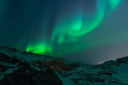

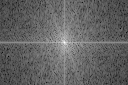

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/07_resim.png"))
display(Image(filename="/content/07_spektrum.png"))

In [ ]:
%%writefile /content/noise_dft.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <filesystem>

using namespace cv;
using namespace std;
namespace fs = std::filesystem;

Mat gaussGurultu(const Mat& img, double sigma) {
    Mat out = img.clone();
    RNG rng(getTickCount());

    if (img.channels() == 1) {
        for (int y = 0; y < img.rows; y++) {
            const uchar* src = img.ptr<uchar>(y);
            uchar* dst = out.ptr<uchar>(y);

            for (int x = 0; x < img.cols; x++) {
                int v = src[x] + cvRound(rng.gaussian(sigma));
                if (v < 0) v = 0;
                if (v > 255) v = 255;
                dst[x] = (uchar)v;
            }
        }
    } else {
        for (int y = 0; y < img.rows; y++) {
            const Vec3b* src = img.ptr<Vec3b>(y);
            Vec3b* dst = out.ptr<Vec3b>(y);

            for (int x = 0; x < img.cols; x++) {
                for (int c = 0; c < 3; c++) {
                    int v = src[x][c] + cvRound(rng.gaussian(sigma));
                    if (v < 0) v = 0;
                    if (v > 255) v = 255;
                    dst[x][c] = (uchar)v;
                }
            }
        }
    }

    return out;
}

Mat tuzBiberGurultu(const Mat& img, double oran) {
    Mat out = img.clone();
    RNG rng(getTickCount() + 12345);

    int adet = (int)(oran * img.rows * img.cols);

    for (int i = 0; i < adet; i++) {
        int y = rng.uniform(0, img.rows);
        int x = rng.uniform(0, img.cols);
        int deger = rng.uniform(0, 2) == 0 ? 0 : 255;

        if (img.channels() == 1) {
            out.ptr<uchar>(y)[x] = (uchar)deger;
        } else {
            out.ptr<Vec3b>(y)[x] = Vec3b(deger, deger, deger);
        }
    }

    return out;
}

Mat DFT2D(const Mat& img) {
    Mat gri;

    if (img.channels() == 3) cvtColor(img, gri, COLOR_BGR2GRAY);
    else gri = img.clone();

    int h = gri.rows;
    int w = gri.cols;
    double pi = acos(-1.0);

    Mat satir(h, w, CV_64FC2, Scalar(0, 0));
    Mat H(h, w, CV_64FC2, Scalar(0, 0));

    for (int y = 0; y < h; y++) {
        for (int u = 0; u < w; u++) {
            double reel = 0;
            double imag = 0;

            for (int x = 0; x < w; x++) {
                double aci = 2.0 * pi * u * x / w;
                double p = gri.ptr<uchar>(y)[x];

                reel += p * cos(aci);
                imag -= p * sin(aci);
            }

            satir.ptr<Vec2d>(y)[u] = Vec2d(reel, imag);
        }
    }

    for (int v = 0; v < h; v++) {
        for (int u = 0; u < w; u++) {
            double reel = 0;
            double imag = 0;

            for (int y = 0; y < h; y++) {
                double aci = 2.0 * pi * v * y / h;
                Vec2d z = satir.ptr<Vec2d>(y)[u];

                reel += z[0] * cos(aci) + z[1] * sin(aci);
                imag += z[1] * cos(aci) - z[0] * sin(aci);
            }

            H.ptr<Vec2d>(v)[u] = Vec2d(reel, imag);
        }
    }

    return H;
}

Mat spektrumGoster(const Mat& H) {
    int h = H.rows;
    int w = H.cols;

    Mat mag(h, w, CV_64FC1, Scalar(0));

    for (int y = 0; y < h; y++) {
        for (int x = 0; x < w; x++) {
            Vec2d z = H.ptr<Vec2d>(y)[x];
            double m = log(1.0 + sqrt(z[0] * z[0] + z[1] * z[1]));

            int yy = (y + h / 2) % h;
            int xx = (x + w / 2) % w;

            mag.ptr<double>(yy)[xx] = m;
        }
    }

    Mat out;
    normalize(mag, out, 0, 255, NORM_MINMAX, CV_8UC1);
    return out;
}

double harmonikFark(const Mat& A, const Mat& B) {
    double toplam = 0;

    for (int y = 0; y < A.rows; y++) {
        for (int x = 0; x < A.cols; x++) {
            Vec2d a = A.ptr<Vec2d>(y)[x];
            Vec2d b = B.ptr<Vec2d>(y)[x];

            toplam += abs(a[0] - b[0]) + abs(a[1] - b[1]);
        }
    }

    return toplam / (A.rows * A.cols);
}

int main() {
    fs::create_directories("/content/results");

    Mat img = imread("/content/image.jpg", IMREAD_COLOR);

    if (img.empty()) {
        cout << "Resim okunamadi" << endl;
        return 1;
    }

    Mat kucuk;
    double oran = min(1.0, 64.0 / max(img.rows, img.cols));
    resize(img, kucuk, Size(), oran, oran, INTER_AREA);

    Mat gri;
    cvtColor(kucuk, gri, COLOR_BGR2GRAY);

    Mat gauss = gaussGurultu(gri, 20.0);
    Mat sp = tuzBiberGurultu(gri, 0.08);

    Mat H_orj = DFT2D(gri);
    Mat H_gauss = DFT2D(gauss);
    Mat H_sp = DFT2D(sp);

    Mat S_orj = spektrumGoster(H_orj);
    Mat S_gauss = spektrumGoster(H_gauss);
    Mat S_sp = spektrumGoster(H_sp);

    double farkGauss = harmonikFark(H_orj, H_gauss);
    double farkSP = harmonikFark(H_orj, H_sp);

    imwrite("/content/results/01_orijinal_gri.png", gri);
    imwrite("/content/results/02_gauss_gurultulu.png", gauss);
    imwrite("/content/results/03_tuz_biber_gurultulu.png", sp);

    imwrite("/content/results/04_orijinal_spektrum.png", S_orj);
    imwrite("/content/results/05_gauss_spektrum.png", S_gauss);
    imwrite("/content/results/06_tuz_biber_spektrum.png", S_sp);

    cout << "Gauss harmonik farki: " << farkGauss << endl;
    cout << "SaltPepper harmonik farki: " << farkSP << endl;
    cout << "Sonuclar /content/results klasorune kaydedildi." << endl;

    return 0;
}

Writing /content/noise_dft.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/noise_dft.cpp -o /content/noise_dft $(pkg-config --cflags --libs opencv4)
!/content/noise_dft

Gauss harmonik farki: 1274.71
SaltPepper harmonik farki: 2401.83
Sonuclar /content/results klasorune kaydedildi.


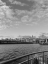

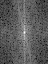

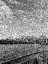

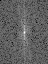

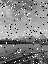

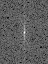

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/results/01_orijinal_gri.png"))
display(Image(filename="/content/results/04_orijinal_spektrum.png"))

display(Image(filename="/content/results/02_gauss_gurultulu.png"))
display(Image(filename="/content/results/05_gauss_spektrum.png"))

display(Image(filename="/content/results/03_tuz_biber_gurultulu.png"))
display(Image(filename="/content/results/06_tuz_biber_spektrum.png"))

In [ ]:
%%writefile /content/ters_dft_zncc.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <filesystem>
#include <iomanip>

using namespace cv;
using namespace std;

Mat gaussGurultu(const Mat& img, double sigma) {
    Mat sonuc = img.clone();
    RNG rng(42);

    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {
            int v = img.ptr<uchar>(y)[x] + cvRound(rng.gaussian(sigma));
            sonuc.ptr<uchar>(y)[x] = (uchar)max(0, min(255, v));
        }
    }
    return sonuc;
}

Mat tuzBiber(const Mat& img, double oran) {
    Mat sonuc = img.clone();
    RNG rng(123);

    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {
            if (rng.uniform(0.0, 1.0) < oran) {
                sonuc.ptr<uchar>(y)[x] = rng.uniform(0, 2) ? 255 : 0;
            }
        }
    }
    return sonuc;
}

Mat fourier2D(const Mat& giris, bool ters) {
    int h = giris.rows, w = giris.cols;
    double pi = acos(-1.0);
    double isaret = ters ? 1.0 : -1.0;

    Mat satir(h, w, CV_64FC2, Scalar(0,0));
    Mat sonuc(h, w, CV_64FC2, Scalar(0,0));

    for (int y = 0; y < h; y++) {
        for (int u = 0; u < w; u++) {
            double reel = 0, imag = 0;

            for (int x = 0; x < w; x++) {
                double aci = isaret*2*pi*u*x/w;
                Vec2d z = giris.ptr<Vec2d>(y)[x];

                reel += z[0]*cos(aci)-z[1]*sin(aci);
                imag += z[0]*sin(aci)+z[1]*cos(aci);
            }

            if (ters) { reel /= w; imag /= w; }
            satir.ptr<Vec2d>(y)[u] = Vec2d(reel, imag);
        }
    }

    for (int v = 0; v < h; v++) {
        for (int u = 0; u < w; u++) {
            double reel = 0, imag = 0;

            for (int y = 0; y < h; y++) {
                double aci = isaret*2*pi*v*y/h;
                Vec2d z = satir.ptr<Vec2d>(y)[u];

                reel += z[0]*cos(aci)-z[1]*sin(aci);
                imag += z[0]*sin(aci)+z[1]*cos(aci);
            }

            if (ters) { reel /= h; imag /= h; }
            sonuc.ptr<Vec2d>(v)[u] = Vec2d(reel, imag);
        }
    }
    return sonuc;
}

Mat kompleksYap(const Mat& img) {
    Mat sonuc(img.rows, img.cols, CV_64FC2);

    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {
            sonuc.ptr<Vec2d>(y)[x] = Vec2d(img.ptr<uchar>(y)[x], 0);
        }
    }
    return sonuc;
}

Mat frekansFiltre(const Mat& H, double esik) {
    Mat sonuc = H.clone();
    double N = H.rows*H.cols;

    for (int y = 0; y < H.rows; y++) {
        for (int x = 0; x < H.cols; x++) {
            Vec2d z = H.ptr<Vec2d>(y)[x];
            double genlik = hypot(z[0], z[1])/N;

            if (genlik < esik) {
                sonuc.ptr<Vec2d>(y)[x] = Vec2d(0,0);
            }
        }
    }
    return sonuc;
}

Mat resimYap(const Mat& H) {
    Mat sonuc(H.rows, H.cols, CV_8UC1);

    for (int y = 0; y < H.rows; y++) {
        for (int x = 0; x < H.cols; x++) {
            int v = cvRound(H.ptr<Vec2d>(y)[x][0]);
            sonuc.ptr<uchar>(y)[x] = (uchar)max(0, min(255, v));
        }
    }
    return sonuc;
}

Mat spektrum(const Mat& H) {
    Mat sonuc(H.rows, H.cols, CV_64F);

    for (int y = 0; y < H.rows; y++) {
        for (int x = 0; x < H.cols; x++) {
            Vec2d z = H.ptr<Vec2d>(y)[x];
            int yy = (y+H.rows/2)%H.rows;
            int xx = (x+H.cols/2)%H.cols;
            sonuc.ptr<double>(yy)[xx] = log(1.0+hypot(z[0], z[1]));
        }
    }

    Mat goster;
    normalize(sonuc, goster, 0, 255, NORM_MINMAX, CV_8UC1);
    return goster;
}

double ZNCC(const Mat& A, const Mat& B) {
    double ortA = mean(A)[0], ortB = mean(B)[0];
    double ust = 0, altA = 0, altB = 0;

    for (int y = 0; y < A.rows; y++) {
        for (int x = 0; x < A.cols; x++) {
            double a = A.ptr<uchar>(y)[x]-ortA;
            double b = B.ptr<uchar>(y)[x]-ortB;

            ust += a*b;
            altA += a*a;
            altB += b*b;
        }
    }

    if (altA == 0 || altB == 0) { return NAN; }
    return ust/sqrt(altA*altB);
}

double MSE(const Mat& A, const Mat& B) {
    double toplam = 0;

    for (int y = 0; y < A.rows; y++) {
        for (int x = 0; x < A.cols; x++) {
            double fark = (double)A.ptr<uchar>(y)[x]-B.ptr<uchar>(y)[x];
            toplam += fark*fark;
        }
    }
    return toplam/(A.rows*A.cols);
}

void test(const Mat& orj, const Mat& gurultulu, string ad, double esik) {
    Mat H = fourier2D(kompleksYap(gurultulu), false);

    Mat direkt = resimYap(fourier2D(H, true));

    Mat HF = frekansFiltre(H, esik);
    Mat filtreli = resimYap(fourier2D(HF, true));

    string yol = "/content/results/" + ad;

    imwrite(yol+"_gurultulu.png", gurultulu);
    imwrite(yol+"_direkt.png", direkt);
    imwrite(yol+"_filtreli.png", filtreli);
    imwrite(yol+"_spektrum.png", spektrum(H));
    imwrite(yol+"_filtre_spektrum.png", spektrum(HF));

    cout << "\n" << ad << endl;
    cout << "Gurultulu ZNCC: " << ZNCC(orj, gurultulu) << endl;
    cout << "Direkt IDFT ZNCC: " << ZNCC(orj, direkt) << endl;
    cout << "Filtreli IDFT ZNCC: " << ZNCC(orj, filtreli) << endl;
    cout << "Gurultulu MSE: " << MSE(orj, gurultulu) << endl;
    cout << "Filtreli MSE: " << MSE(orj, filtreli) << endl;
}

int main() {
    std::filesystem::create_directories("/content/results");

    Mat img = imread("/content/image.jpg", IMREAD_GRAYSCALE);
    if (img.empty()) { cout << "Resim bulunamadi"; return 1; }

    Mat orj;
    double oran = min(1.0, 64.0/max(img.rows, img.cols));
    resize(img, orj, Size(), oran, oran, INTER_AREA);

    Mat gauss = gaussGurultu(orj, 20.0);
    Mat sp = tuzBiber(orj, 0.08);

    double esik = 0.5;

    imwrite("/content/results/orijinal.png", orj);

    cout << fixed << setprecision(5);
    cout << "Frekans esigi: " << esik << endl;

    test(orj, gauss, "gauss", esik);
    test(orj, sp, "saltpepper", esik);

    return 0;
}

Writing /content/ters_dft_zncc.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/ters_dft_zncc.cpp -o /content/ters_dft $(pkg-config --cflags --libs opencv4) && /content/ters_dft

Frekans esigi: 0.50000

gauss
Gurultulu ZNCC: 0.92076
Direkt IDFT ZNCC: 0.92076
Filtreli IDFT ZNCC: 0.93388
Gurultulu MSE: 393.19499
Filtreli MSE: 304.02344

saltpepper
Gurultulu ZNCC: 0.76303
Direkt IDFT ZNCC: 0.76303
Filtreli IDFT ZNCC: 0.77670
Gurultulu MSE: 1381.18587
Filtreli MSE: 1247.18652


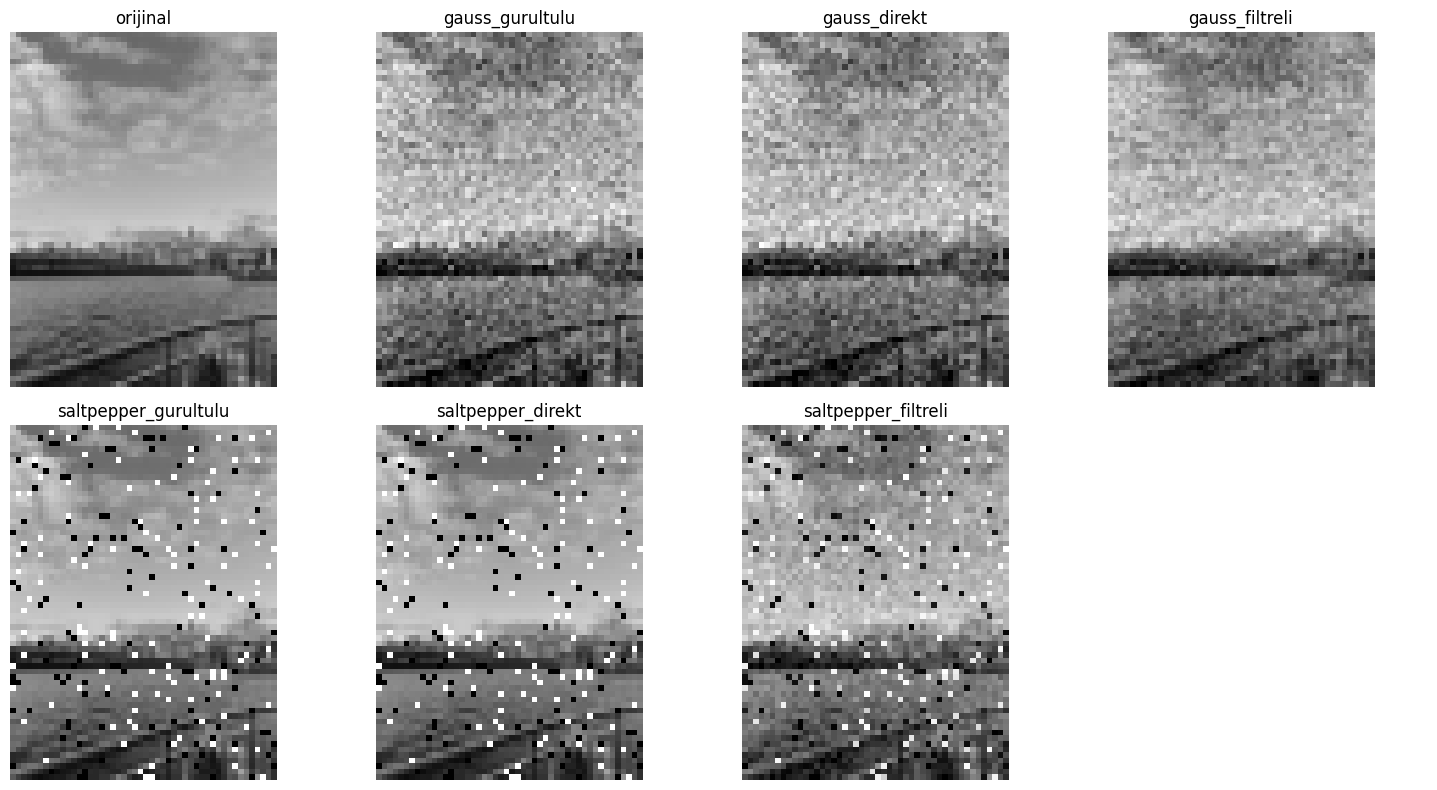

In [ ]:
import cv2
import matplotlib.pyplot as plt

dossier = "/content/results/"
noms = ["orijinal.png",
        "gauss_gurultulu.png", "gauss_direkt.png", "gauss_filtreli.png",
        "saltpepper_gurultulu.png", "saltpepper_direkt.png",
        "saltpepper_filtreli.png"]

fig, ax = plt.subplots(2, 4, figsize=(15, 8))

for i, ad in enumerate(noms):
    ligne = i // 4
    colonne = i % 4
    img = cv2.imread(dossier + ad, 0)
    ax[ligne, colonne].imshow(img, cmap="gray", vmin=0, vmax=255)
    ax[ligne, colonne].set_title(ad.replace(".png", ""))
    ax[ligne, colonne].axis("off")

ax[1, 3].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
%%writefile /content/frekans_filtreleri.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <filesystem>
#include <cmath>
#include <iomanip>

using namespace cv;
using namespace std;
namespace fs = std::filesystem;

Mat gaussGurultu(const Mat& img, double sigma) {
    Mat sonuc = img.clone();
    RNG rng(42);

    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {
            int v = img.ptr<uchar>(y)[x] + cvRound(rng.gaussian(sigma));
            sonuc.ptr<uchar>(y)[x] = (uchar)max(0, min(255, v));
        }
    }
    return sonuc;
}

Mat tuzBiber(const Mat& img, double oran) {
    Mat sonuc = img.clone();
    RNG rng(123);

    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {
            if (rng.uniform(0.0, 1.0) < oran) {
                sonuc.ptr<uchar>(y)[x] = rng.uniform(0,2) ? 255 : 0;
            }
        }
    }
    return sonuc;
}

Mat filtreMaskesi(Size boyut, int tip, double d1, double d2) {
    Mat maske(boyut, CV_32F, Scalar(0));

    for (int y = 0; y < boyut.height; y++) {
        for (int x = 0; x < boyut.width; x++) {
            double fx = (x <= boyut.width/2 ? x : x-boyut.width);
            double fy = (y <= boyut.height/2 ? y : y-boyut.height);

            fx /= boyut.width;
            fy /= boyut.height;

            double d = sqrt(fx*fx + fy*fy);
            bool gecir = false;

            if (tip == 0) { gecir = d <= d1; }
            if (tip == 1) { gecir = d > d1; }
            if (tip == 2) { gecir = d >= d1 && d <= d2; }
            if (tip == 3) { gecir = d < d1 || d > d2; }

            maske.ptr<float>(y)[x] = gecir ? 1.0f : 0.0f;
        }
    }

    return maske;
}

Mat frekansFiltre(const Mat& img, int tip, double d1, double d2) {
    Mat reel;
    img.convertTo(reel, CV_32F);

    Mat H;
    dft(reel, H, DFT_COMPLEX_OUTPUT);

    Mat maske = filtreMaskesi(img.size(), tip, d1, d2);

    for (int y = 0; y < H.rows; y++) {
        for (int x = 0; x < H.cols; x++) {
            float katsayi = maske.ptr<float>(y)[x];
            H.ptr<Vec2f>(y)[x][0] *= katsayi;
            H.ptr<Vec2f>(y)[x][1] *= katsayi;
        }
    }

    Mat sonuc;
    idft(H, sonuc, DFT_REAL_OUTPUT | DFT_SCALE);

    if (tip == 1 || tip == 2) {
        sonuc += 128.0f;
    }

    Mat goster;
    sonuc.convertTo(goster, CV_8U);
    return goster;
}

void test(const Mat& img, string ad) {
    string yol = "/content/results/" + ad;

    Mat lp = frekansFiltre(img, 0, 0.12, 0);
    Mat hp = frekansFiltre(img, 1, 0.12, 0);
    Mat bp = frekansFiltre(img, 2, 0.08, 0.25);
    Mat br = frekansFiltre(img, 3, 0.08, 0.25);

    imwrite(yol+"_original.png", img);
    imwrite(yol+"_lowpass.png", lp);
    imwrite(yol+"_highpass.png", hp);
    imwrite(yol+"_bandpass.png", bp);
    imwrite(yol+"_bandreject.png", br);

    cout << "\n" << ad << endl;
    cout << "Giris parlaklik: " << mean(img)[0] << endl;
    cout << "Low-Pass: " << mean(lp)[0] << endl;
    cout << "High-Pass (gosterim): " << mean(hp)[0] << endl;
    cout << "Band-Pass (gosterim): " << mean(bp)[0] << endl;
    cout << "Band-Reject: " << mean(br)[0] << endl;
}

int main() {
    fs::create_directories("/content/results");

    Mat img = imread("/content/image.jpg", IMREAD_GRAYSCALE);
    if (img.empty()) {
        cout << "Resim bulunamadi" << endl;
        return 1;
    }

    Mat orj;
    double oran = min(1.0, 256.0 / max(img.rows, img.cols));
    resize(img, orj, Size(), oran, oran, INTER_AREA);

    Mat gauss = gaussGurultu(orj, 20.0);
    Mat sp = tuzBiber(orj, 0.08);

    cout << fixed << setprecision(2);

    test(orj, "orijinal");
    test(gauss, "gauss");
    test(sp, "saltpepper");

    cout << "\nFiltreleme tamamlandi" << endl;
    return 0;
}

Writing /content/frekans_filtreleri.cpp


In [ ]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config
!g++ -std=c++17 -O2 /content/frekans_filtreleri.cpp -o /content/frekans_filtreleri $(pkg-config --cflags --libs opencv4) && /content/frekans_filtreleri

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 10 not upgraded.

orijinal
Giris parlaklik: 134.49
Low-Pass: 134.49
High-Pass (gosterim): 128.00
Band-Pass (gosterim): 128.00
Band-Reject: 134.49

gauss
Giris parlaklik: 134.46
Low-Pass: 134.46
High-Pass (gosterim): 128.00
Band-Pass (gosterim): 128.00
Band-Reject: 134.49

saltpepper
Giris parlaklik: 133.87
Low-Pass: 133.87
High-Pass (gosterim): 128.20
Band-Pass (gosterim): 128.00
Band-Reject: 133.91

Filtreleme tamamlandi


In [ ]:
!mkdir -p /content/results
!ls -lh /content/image.jpg
!ls -lh /content/frekans_filtreleri.cpp

-rw-r--r-- 1 root root 4.0K Nov  2 14:41 /content/image.jpg
-rw-r--r-- 1 root root 3.7K Nov  2 14:45 /content/frekans_filtreleri.cpp


In [ ]:
!g++ -std=c++17 -O2 /content/frekans_filtreleri.cpp -o /content/filtre $(pkg-config --cflags --libs opencv4) && /content/filtre


orijinal
Giris parlaklik: 54.88
Low-Pass: 54.88
High-Pass (gosterim): 128.00
Band-Pass (gosterim): 128.00
Band-Reject: 54.88

gauss
Giris parlaklik: 55.41
Low-Pass: 55.41
High-Pass (gosterim): 128.00
Band-Pass (gosterim): 128.00
Band-Reject: 55.52

saltpepper
Giris parlaklik: 60.72
Low-Pass: 60.73
High-Pass (gosterim): 125.64
Band-Pass (gosterim): 128.00
Band-Reject: 61.32

Filtreleme tamamlandi


In [ ]:
!ls -lh /content/results/*.png

-rw-r--r-- 1 root root 27K Nov  2 14:47 /content/results/gauss_bandpass.png
-rw-r--r-- 1 root root 37K Nov  2 14:47 /content/results/gauss_bandreject.png
-rw-r--r-- 1 root root 37K Nov  2 14:47 /content/results/gauss_highpass.png
-rw-r--r-- 1 root root 19K Nov  2 14:47 /content/results/gauss_lowpass.png
-rw-r--r-- 1 root root 37K Nov  2 14:47 /content/results/gauss_original.png
-rw-r--r-- 1 root root 17K Nov  2 14:47 /content/results/orijinal_bandpass.png
-rw-r--r-- 1 root root 18K Nov  2 14:47 /content/results/orijinal_bandreject.png
-rw-r--r-- 1 root root 18K Nov  2 14:47 /content/results/orijinal_highpass.png
-rw-r--r-- 1 root root 16K Nov  2 14:47 /content/results/orijinal_lowpass.png
-rw-r--r-- 1 root root 17K Nov  2 14:47 /content/results/orijinal_original.png
-rw-r--r-- 1 root root 32K Nov  2 14:47 /content/results/saltpepper_bandpass.png
-rw-r--r-- 1 root root 35K Nov  2 14:47 /content/results/saltpepper_bandreject.png
-rw-r--r-- 1 root root 29K Nov  2 14:47 /content/results/sa

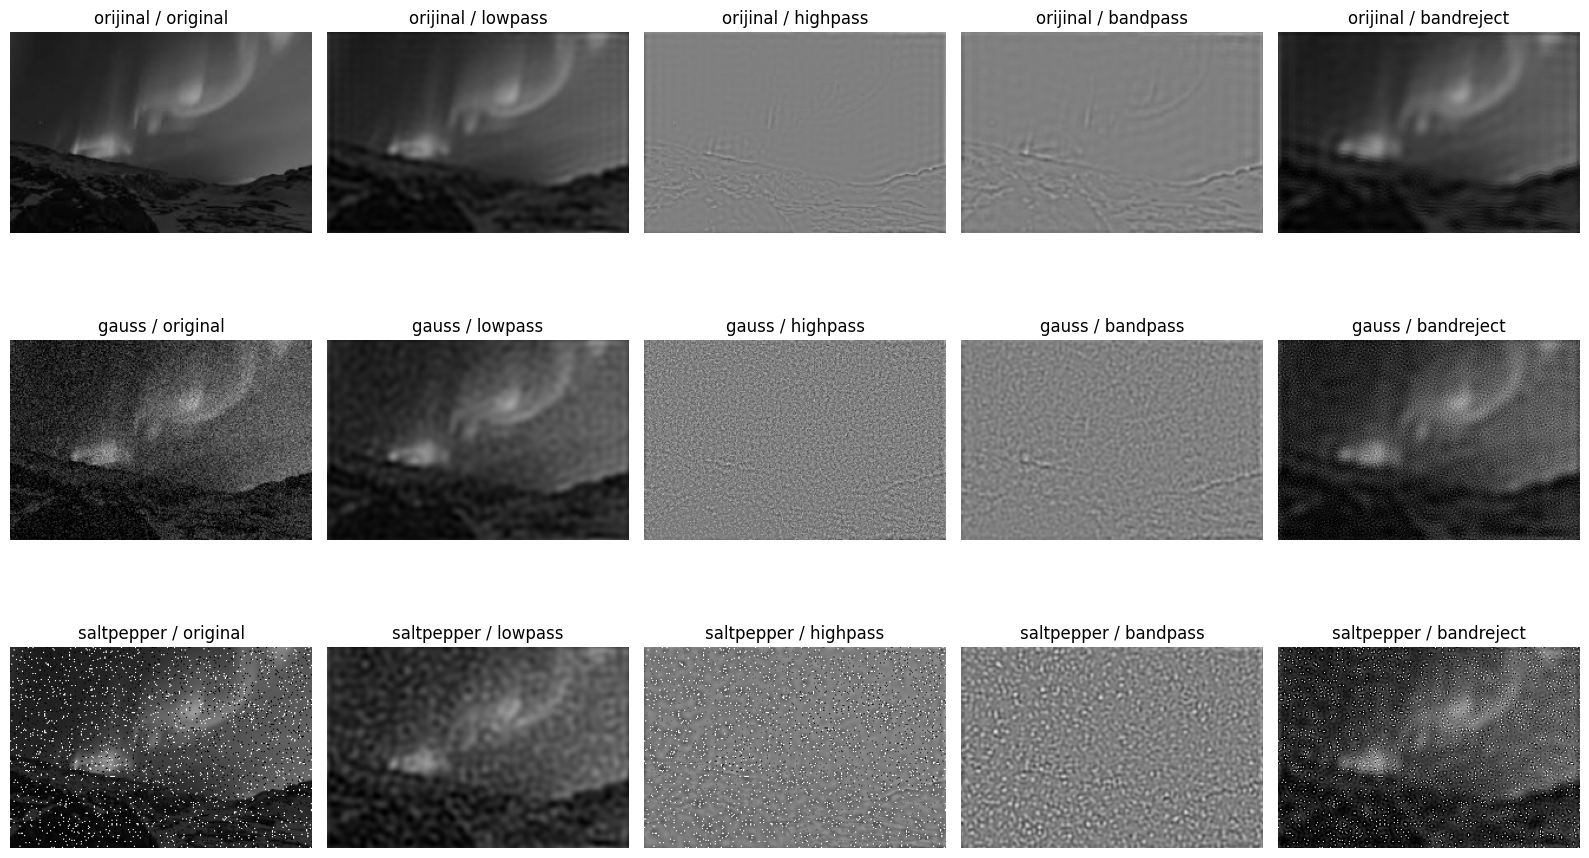

In [ ]:
import cv2
import matplotlib.pyplot as plt

images = ["orijinal", "gauss", "saltpepper"]
filtres = ["original", "lowpass", "highpass", "bandpass", "bandreject"]

fig, ax = plt.subplots(3, 5, figsize=(16, 10))

for i in range(3):
    for j in range(5):
        chemin = "/content/results/" + images[i] + "_" + filtres[j] + ".png"
        img = cv2.imread(chemin, 0)

        if img is not None:
            ax[i,j].imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            print("Image manquante :", chemin)

        ax[i,j].set_title(images[i] + " / " + filtres[j])
        ax[i,j].axis("off")

plt.tight_layout()
plt.savefig("/content/frekans_filtre_sonuclari.png", dpi=200)
plt.show()

In [ ]:
import os

noms = [
    "1_sinus_vektor.cpp",
    "urultu_ekle.cpp",
    "gauss_medyan.cpp",
    "dft_harmonik.cpp",
    "dft_iki_sinyal.cpp",
    "frekans_filtresi.cpp",
    "dft_2d.cpp",
    "noise_dft.cpp",
    "ters_dft_zncc.cpp",
    "frekans_filtreleri.cpp"
]

for nom in noms:
    chemin = "/content/" + nom
    print(("OK : " if os.path.isfile(chemin) else "MANQUANT : ") + nom)

MANQUANT : 1_sinus_vektor.cpp
MANQUANT : urultu_ekle.cpp
MANQUANT : gauss_medyan.cpp
OK : dft_harmonik.cpp
MANQUANT : dft_iki_sinyal.cpp
MANQUANT : frekans_filtresi.cpp
MANQUANT : dft_2d.cpp
MANQUANT : noise_dft.cpp
MANQUANT : ters_dft_zncc.cpp
MANQUANT : frekans_filtreleri.cpp


In [ ]:
import zipfile
from google.colab import files

zip_path = "/content/devoir_traitement_images.zip"
ajoutes = 0

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for nom in noms:
        chemin = "/content/" + nom
        if os.path.isfile(chemin):
            archive.write(chemin, "devoir_traitement_images/" + nom)
            ajoutes += 1

print("Fichiers ajoutés :", ajoutes, "/ 10")

if ajoutes == 10:
    files.download(zip_path)
else:
    print("ZIP incomplet : recrée les fichiers manquants avant de l'envoyer.")

Fichiers ajoutés : 1 / 10
ZIP incomplet : recrée les fichiers manquants avant de l'envoyer.


In [ ]:
import os

for dossier, sous_dossiers, fichiers in os.walk("/content"):
    for fichier in fichiers:
        if fichier.endswith((".cpp", ".cu")):
            print(os.path.join(dossier, fichier))

In [ ]:
%%writefile /content/dft_harmonik.cpp
#include <iostream>
using namespace std;

int main() {
    cout << "Test" << endl;
    return 0;
}

Overwriting /content/dft_harmonik.cpp


In [ ]:
!head -n 15 /content/dft_harmonik.cpp

#include <iostream>
using namespace std;

int main() {
    cout << "Test" << endl;
    return 0;
}
